In [1]:
import os
import cv2
import urllib
import itertools
import numpy as np
import pandas as pd
import seaborn as sns
import random,os,glob
from imutils import paths
import matplotlib.pyplot as plt
from sklearn.utils import shuffle
from urllib.request import urlopen

import warnings
warnings.filterwarnings("ignore")

from sklearn.metrics import confusion_matrix,classification_report

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.preprocessing import image
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import ModelCheckpoint,EarlyStopping
from tensorflow.keras.layers import Flatten,MaxPooling2D,Dense,Dropout,SpatialDropout2D
from tensorflow.keras.preprocessing.image import ImageDataGenerator,img_to_array,load_img,array_to_img

In [2]:
waste_labels = {
    'cardboard':0,
    'glass':1,
    'metal':2,
    'paper':3,
    'plastic':4,
    'trash':5
}

In [3]:
target_size = (224,224)

In [4]:
def load_dataset(path):
    x = []
    labels = []

    image_paths = sorted(list(paths.list_images(path)))

    for image_path in image_paths:

        img = cv2.imread(image_path)

        img = cv2.resize(img,target_size)

        x.append(img)

        label = image_path.split(os.path.sep)[-2]

        labels.append(waste_labels[label])

    x,labels = shuffle(x,labels,random_state=15)

    print(f"X shape: {np.array(x).shape}")
    print(f"Label classes: {len(np.unique(labels))} Numbers: {len(labels)}")

    return x,labels

In [5]:
dir_path = 'Garbage classification'
x,labels = load_dataset(dir_path)

X shape: (2527, 224, 224, 3)
Label classes: 6 Numbers: 2527


In [6]:
input_shape = (np.array(x[0]).shape[1], np.array(x[0]).shape[1],3)

In [7]:
input_shape

(224, 224, 3)

In [8]:
def visualize_img(image_batch,label_batch):
    plt.figure(figsize=(10,10))
    for n in range(10):
        ax = plt.subplot(5,5,n+1)
        plt.imshow(image_batch[n])
        plt.title(np.array(list(waste_labels.keys()))[to_categorical(labels,num_classes=6)[n]==1][0].title())
        plt.axis('off')
    plt.show()

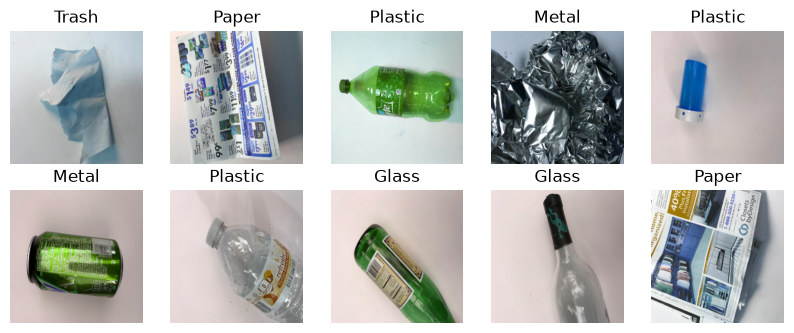

In [9]:
visualize_img(x,labels)

In [10]:
train = ImageDataGenerator(
    horizontal_flip=True,
    vertical_flip=True,
    validation_split=0.1,
    rescale=1./255,
    shear_range=0.1,
    zoom_range=0.1,
    width_shift_range=0.1,
    height_shift_range=0.1
)

test = ImageDataGenerator(
    rescale=1/255,
    validation_split=0.1
)

In [11]:
train_generator = train.flow_from_directory(
    directory=dir_path,
    target_size=(target_size),
    class_mode='categorical',
    subset='training'
)

test_generator = test.flow_from_directory(
    directory=dir_path,
    target_size=(target_size),
    batch_size=251,
    class_mode='categorical',
    subset='validation'
)

Found 2276 images belonging to 6 classes.
Found 251 images belonging to 6 classes.


## Modelling

In [12]:
model = Sequential()

In [19]:
from tensorflow.keras.layers import Conv2D

In [20]:
model.add(Conv2D(filters=32, kernel_size=(3,3), padding='same', input_shape=(input_shape), activation='relu'))

In [21]:
model.add(MaxPooling2D(pool_size=2,strides=(2,2)))

In [22]:
model.add(Conv2D(filters=64, kernel_size=(3,3), padding='same', input_shape=(input_shape), activation='relu'))

In [23]:
model.add(MaxPooling2D(pool_size=2,strides=(2,2)))

In [24]:
model.add(Conv2D(filters=64, kernel_size=(3,3), padding='same', input_shape=(input_shape), activation='relu'))

In [25]:
model.add(MaxPooling2D(pool_size=2,strides=(2,2)))

In [26]:
model.add(Flatten())

In [27]:
model.add(Dense(units=64,activation='relu'))

In [28]:
model.add(Dropout(rate=0.2))

In [30]:
model.add(Dense(units=32,activation='relu'))

In [31]:
model.add(Dropout(rate=0.2))

In [32]:
model.add(Dense(units=6, activation='softmax'))

In [33]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 224, 224, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 112, 112, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 112, 112, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 56, 56, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 56, 56, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 28, 28, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 50176)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │       3,211,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 6)                   │             198 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,269,926 (12.47 MB)

 Trainable params: 3,269,926 (12.47 MB)

 Non-trainable params: 0 (0.00 B)

In [41]:
model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=[tf.keras.metrics.Precision(), tf.keras.metrics.Recall(), "acc"]
)

In [42]:
callbacks = [
    EarlyStopping(monitor='val_loss',patience=50,verbose=1,mode="min"),
    ModelCheckpoint(filepath='mymodel.keras',monitor='val_loss',mode='min',save_best_only=True,save_weights_only=False,verbose=1)
]

In [43]:
history = model.fit(
    train_generator,
    epochs=100,
    validation_data=test_generator,
    callbacks=callbacks,
    steps_per_epoch=2276 // 32,
    validation_steps=251 // 32
)

Epoch 1/100
71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - acc: 0.2331 - loss: 1.7593 - precision_1: 0.2632 - recall_1: 0.0022
Epoch 1: val_loss improved from None to 1.71523, saving model to mymodel.keras

Epoch 1: finished saving model to mymodel.keras
71/71 ━━━━━━━━━━━━━━━━━━━━ 171s 2s/step - acc: 0.2331 - loss: 1.7593 - precision_1: 0.2632 - recall_1: 0.0022 - val_acc: 0.2351 - val_loss: 1.7152 - val_precision_1: 0.0000e+00 - val_recall_1: 0.0000e+00
Epoch 2/100
 1/71 ━━━━━━━━━━━━━━━━━━━━ 1:47 2s/step - acc: 0.2500 - loss: 1.7322 - precision_1: 0.0000e+00 - recall_1: 0.0000e+00
Epoch 2: val_loss improved from 1.71523 to 1.71224, saving model to mymodel.keras

Epoch 2: finished saving model to mymodel.keras
71/71 ━━━━━━━━━━━━━━━━━━━━ 6s 70ms/step - acc: 0.2500 - loss: 1.7322 - precision_1: 0.0000e+00 - recall_1: 0.0000e+00 - val_acc: 0.2351 - val_loss: 1.7122 - val_precision_1: 0.0000e+00 - val_recall_1: 0.0000e+00
Epoch 3/100
71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - acc: 0.2455 - loss: 1.7

## Accuracy and Loss Graphs

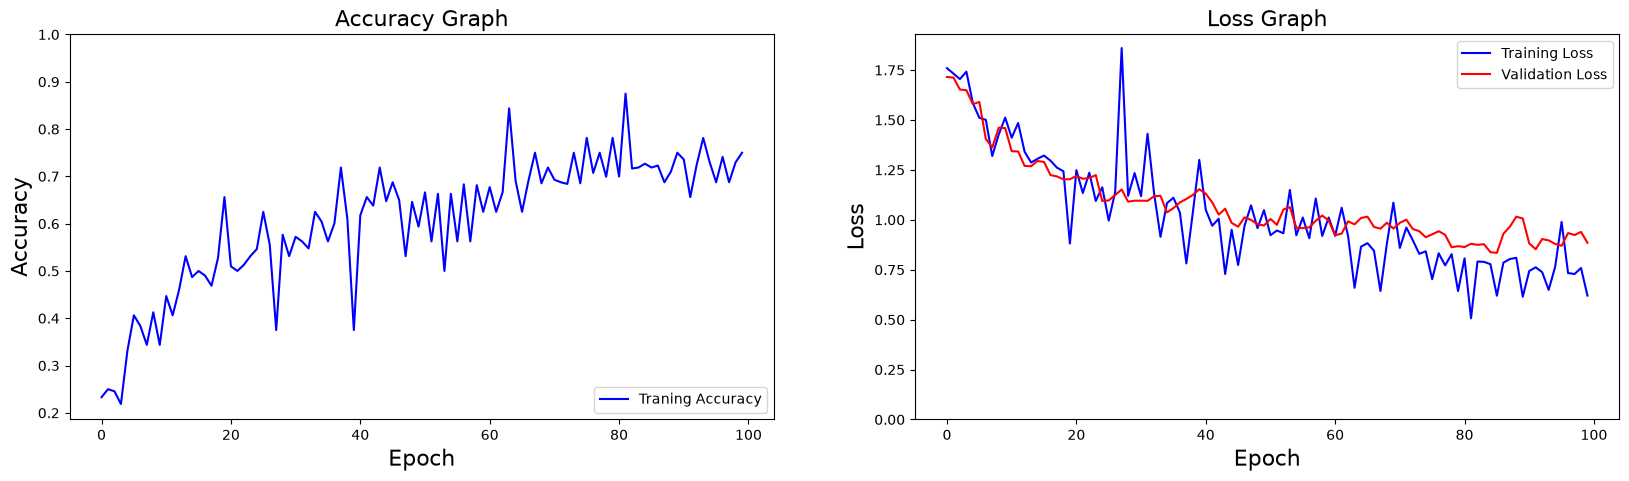

In [45]:
# ------------------------ Graphic 1 ACCURACY ----------------------------

plt.figure(figsize=(20,5))
plt.subplot(1,2,1)
plt.plot(history.history['acc'],color='b',label="Traning Accuracy")
plt.legend(loc="lower right")
plt.xlabel('Epoch', fontsize=16)
plt.ylabel('Accuracy', fontsize=16)
plt.ylim([min(plt.ylim()),1])
plt.title("Accuracy Graph", fontsize=16)

# ------------------------ Graphic 2 LOSS --------------------------------

plt.subplot(1,2,2)
plt.plot(history.history['loss'], color='b', label='Training Loss')
plt.plot(history.history['val_loss'], color='r', label='Validation Loss')
plt.legend(loc="upper right")
plt.xlabel('Epoch', fontsize=16)
plt.ylabel('Loss', fontsize=16)
plt.ylim([0,max(plt.ylim())])
plt.title("Loss Graph", fontsize=16)

plt.show()

# Evaluation

In [49]:
loss,precision,recall,acc = model.evaluate(test_generator,batch_size=32)

1/1 ━━━━━━━━━━━━━━━━━━━━ 16s 16s/step - acc: 0.6693 - loss: 0.8851 - precision_1: 0.8140 - recall_1: 0.5578


In [58]:
X_test, y_test = next(test_generator)

In [59]:
loss, precision, recall, acc = model.evaluate(X_test,y_test, verbose=False)
print("Test Accuracy: %.1f%%" % (100.0 * acc))
print("Test Loss: %.1f%%" % (100.0 * loss))
print("Test Precision: %.1f%%" % (100.0 * precision))
print("Test Recall: %.1f%%" %  (100.0 * recall))

Test Accuracy: 66.9%
Test Loss: 88.5%
Test Precision: 81.4%
Test Recall: 55.8%


In [60]:
y_pred = model.predict(X_test)

8/8 ━━━━━━━━━━━━━━━━━━━━ 5s 622ms/step


In [61]:
y_pred = np.argmax(y_pred,axis=1)

In [62]:
y_test = np.argmax(y_test,axis=1)

In [63]:
target_names = list(waste_labels.keys())

In [64]:
print(classification_report(y_test,y_pred,target_names=target_names))

              precision    recall  f1-score   support

   cardboard       0.79      0.68      0.73        40
       glass       0.63      0.72      0.67        50
       metal       0.52      0.66      0.58        41
       paper       0.83      0.90      0.86        59
     plastic       0.59      0.35      0.44        48
       trash       0.53      0.62      0.57        13

    accuracy                           0.67       251
   macro avg       0.65      0.65      0.64       251
weighted avg       0.67      0.67      0.66       251



In [71]:
def plot_confusion_matrix(cm,classes,normalize=False,title='Confusion Matrix',cmap=plt.cm.Blues):
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:,np.newaxis]

    plt.figure(figsize=(6,6))
    plt.imshow(cm,interpolation='nearest',cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks,classes,rotation=45)
    plt.yticks(tick_marks,classes)
    fmt = '.2f' if normalize else 'd'
    thresh = cm.max() / 2.
    for i,j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j,i,format(cm[i,j]),fmt,
            horizontalalignment="center",
            color="white" if cm[i,j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True Label', fontweight='bold')
    plt.xlabel('Predicted Label', fontweight='bold')
    plt.show()    

In [72]:
cm = confusion_matrix(y_test,y_pred)

TypeError: 'str' object is not a mapping

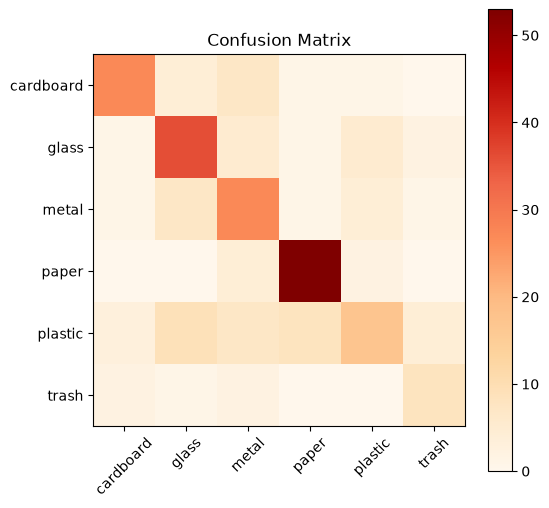

In [73]:
plot_confusion_matrix(cm,waste_labels.keys(),title='Confusion Matrix',cmap=plt.cm.OrRd)